# 3. Fins and extended surfaces

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 2

When the heat transfer coefficient is small, as it is in air, the only way to move more
heat from a surface at a given temperature is to give it more area. Fins do this. This
chapter asks three questions. A power module dissipating 150 W must stay below 90 °C in
air at 40 °C: what heat sink will do it? How should a fixed amount of aluminium be shaped
to carry the most heat? And a concrete balcony slab, which is a fin nobody wanted: how
much heat does it leak from a well-insulated building in an Astana winter?

The theory of fins rests on one assumption: that the temperature is uniform across the
thickness of the fin. The balcony slab is thick enough to test it, and the test is made
with the exact two-dimensional solution and with two-dimensional finite volumes.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

try:
    from engtransport import fins, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import fins, reference
from engtransport.plotting import panel_label, use_style

use_style()

## 3.1 The fin equation

A fin is a solid that sticks out from a surface into a fluid. Heat enters at its base by
conduction, flows along it, and leaves through its sides by convection. Let $x$ run along
the fin from the base, let $A_c$ be the area of its cross-section and $P$ its perimeter.
If the temperature $T(x)$ is uniform over each cross-section, a steady energy balance on
the slice between $x$ and $x + dx$ says that the conduction in, $-kA_c\,dT/dx$ at $x$,
minus the conduction out at $x + dx$, equals the convection from the sides, $hP\,dx\,(T -
T_\infty)$:

$$
\frac{d}{dx}\left(k A_c \frac{dT}{dx}\right) - hP\,(T - T_\infty) = 0 .
\tag{3.1}
$$

For a fin of constant cross-section and constant $k$ and $h$, the excess temperature
$\theta = T - T_\infty$ obeys

$$
\frac{d^2\theta}{dx^2} = m^2\,\theta, \qquad m = \sqrt{\frac{hP}{kA_c}} .
\tag{3.2}
$$

The length $1/m$ is the distance over which the fin does its work: the balance between
conduction along the fin ($kA_c$) and loss from its sides ($hP$). For a plate fin of
thickness $t$, much wider than it is thick, $P/A_c = 2/t$ and $m = \sqrt{2h/kt}$.

## 3.2 Solutions, efficiency and effectiveness

The general solution of Eq. (3.2) is $\theta = C_1 \cosh mx + C_2 \sinh mx$, with the
constants set by the temperature $\theta_b$ at the base and by what happens at the tip.
If the tip loses little heat, take it as adiabatic, $d\theta/dx = 0$ at $x = L$; then

$$
\frac{\theta}{\theta_b} = \frac{\cosh m(L - x)}{\cosh mL}, \qquad
q_f = -kA_c\,\frac{d\theta}{dx}\bigg|_{x=0} = M \tanh mL, \qquad
M = \sqrt{hPkA_c}\;\theta_b .
\tag{3.3}
$$

A tip that does lose heat by convection gives a longer formula, but it is very nearly the
adiabatic one for a fin lengthened by enough to expose the area of the tip on its sides,

$$
L_c = L + \frac{A_c}{P} \qquad (L + t/2 \text{ for a plate fin}) .
\tag{3.4}
$$

When $mL$ is large, $\tanh mL \to 1$ and the fin behaves as if it were infinitely long,
with $q_f = M$; the far end is then at the fluid temperature and does nothing. The heat
carried is within 1 % of this limit once $mL > 2.65$.

Two numbers judge a fin. Its *efficiency* compares the heat it carries with the heat it
would carry if the whole of it were at the base temperature,

$$
\eta_f = \frac{q_f}{hA_f\theta_b} = \frac{\tanh mL_c}{mL_c},
\tag{3.5}
$$

with $A_f = PL_c$ its area. Its *effectiveness* compares the heat with what the bare base
area would have lost without the fin,

$$
\varepsilon_f = \frac{q_f}{hA_c\theta_b} = \sqrt{\frac{kP}{hA_c}}\;\tanh mL_c .
\tag{3.6}
$$

A fin is worth adding only if $\varepsilon_f$ is well above 1, which needs $kP/hA_c$ to be
large: a good conductor, thin, in a fluid with a small $h$. This is why fins go on the air
side of a car radiator and not on the water side.

The heat sink of the next section has aluminium fins, $k = 200$ W/(m K), 2 mm thick and
40 mm high, in air with $h = 40$ W/(m² K):

In [2]:
k_al, h_air, t_fin, H_fin = 200.0, 40.0, 2e-3, 0.040
m = math.sqrt(2 * h_air / (k_al * t_fin))
Hc = H_fin + t_fin / 2
eta = math.tanh(m * Hc) / (m * Hc)
eps_f = math.sqrt(2 * k_al / (h_air * t_fin)) * math.tanh(m * Hc)
print(f"m = {m:.2f} 1/m, 1/m = {1e3 / m:.0f} mm, m Hc = {m * Hc:.3f}")
print(f"efficiency {eta:.3f}, effectiveness {eps_f:.0f}")

# exact convective tip against the corrected length, per metre of fin width
M = math.sqrt(h_air * 2 * k_al * t_fin)            # theta_b = 1 K
ratio = h_air / (m * k_al)
q_tip = M * (math.sinh(m * H_fin) + ratio * math.cosh(m * H_fin)) / (math.cosh(m * H_fin) + ratio * math.sinh(m * H_fin))
print(f"corrected length vs convective tip: {M * math.tanh(m * Hc) / q_tip - 1:+.1e};"
      f" adiabatic tip without correction: {M * math.tanh(m * H_fin) / q_tip - 1:+.1%}")

m = 14.14 1/m, 1/m = 71 mm, m Hc = 0.580
efficiency 0.901, effectiveness 37
corrected length vs convective tip: -1.3e-06; adiabatic tip without correction: -2.0%


The fin is short compared with $1/m = 71$ mm, so it is 90 % efficient: its tip is nearly
as hot as its base. Each fin carries 37 times what the strip of base it stands on would
lose without it. The corrected length (3.4) reproduces the exact convective tip to
$10^{-6}$; ignoring the tip altogether would lose 2 % of the heat.

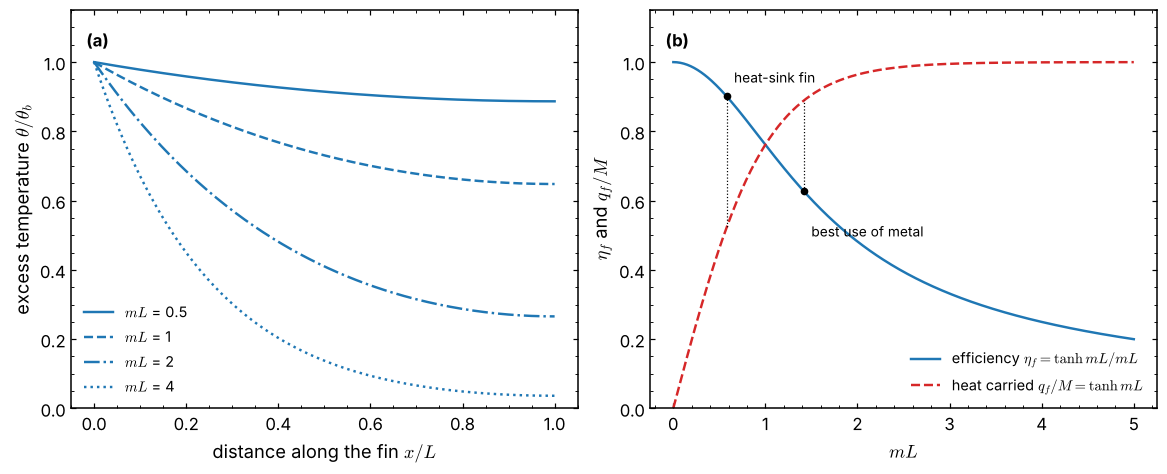

In [3]:
mL = np.linspace(1e-3, 5, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
xs = np.linspace(0, 1, 200)
for val, style in ((0.5, "-"), (1.0, "--"), (2.0, "-."), (4.0, ":")):
    ax1.plot(xs, np.cosh(val * (1 - xs)) / np.cosh(val), "C0" + style, label=f"$mL$ = {val:g}")
ax1.set_xlabel(r"distance along the fin $x/L$")
ax1.set_ylabel(r"excess temperature $\theta/\theta_b$")
ax1.set_ylim(0, 1.15)
ax1.legend(loc="lower left")
panel_label(ax1, "(a)")

ax2.plot(mL, np.tanh(mL) / mL, "C0", label=r"efficiency $\eta_f = \tanh mL / mL$")
ax2.plot(mL, np.tanh(mL), "C3--", label=r"heat carried $q_f / M = \tanh mL$")
for val, name, dy in ((m * Hc, "heat-sink fin", 0.04), (1.4192, "best use of metal", -0.13)):
    ax2.plot([val, val], [np.tanh(val) / val, np.tanh(val)], "k:", lw=0.8)
    ax2.plot([val], [np.tanh(val) / val], "ko", ms=4)
    ax2.text(val + 0.08, np.tanh(val) / val + dy, name, fontsize=9)
ax2.set_xlabel(r"$mL$")
ax2.set_ylabel(r"$\eta_f$ and $q_f/M$")
ax2.set_ylim(0, 1.15)
ax2.legend(loc="lower right")
panel_label(ax2, "(b)")
plt.show()

**Figure 3.1.** (a) Temperature along a fin with an adiabatic tip, Eq. (3.3), for four
values of $mL$. (b) The efficiency of the fin falls as it gets longer, while the heat it
carries rises towards that of an infinitely long fin, $M$. The points mark the fins of the
heat sink of Section 3.3 and the shape that carries the most heat for its mass
(Section 3.4).

## 3.3 A heat sink for a power module

A power module (the transistors of an inverter, for example) dissipates 150 W into the
aluminium base of a heat sink, 100 mm by 100 mm. A fan blows air at 40 °C along it, and
we take $h = 40$ W/(m² K) on every surface. The base must stay below 90 °C, so the heat
sink may have a thermal resistance of at most $(90 - 40)/150 = 0.333$ K/W. The bare base
has $1/hA = 2.5$ K/W, seven times too much.

Plate fins of height $H$ and thickness $t$ run the length of the base. With $N$ of them,
the total area $A_t$ is that of the fins, $NA_f$, plus the strips of base between them. All
of this area is at the base temperature except the fins, which are at an average excess
temperature of $\eta_f\theta_b$. The heat sink therefore loses $q = h(A_t - NA_f +
\eta_fNA_f)\theta_b$, which defines an *overall surface efficiency* $\eta_o$ and a
resistance:

$$
R_t = \frac{\theta_b}{q} = \frac{1}{\eta_o h A_t}, \qquad
\eta_o = 1 - \frac{NA_f}{A_t}\,(1 - \eta_f) .
\tag{3.7}
$$

`fins.plate_fin_heat_sink` evaluates Eq. (3.7):

In [4]:
P_mod, T_air, T_max = 150.0, 40.0, 90.0
length, width = 0.100, 0.100
print(f"allowed resistance {(T_max - T_air) / P_mod:.3f} K/W; bare base {1 / (h_air * length * width):.2f} K/W")
print(" N   R (K/W)  T_base (C)   eta_o   gap (mm)")
for N in (5, 8, 10, 12, 15):
    s = fins.plate_fin_heat_sink(N, H_fin, t_fin, length, width, k_al, h_air)
    print(f"{N:2d}   {s['R']:.3f}     {T_air + P_mod * s['R']:6.1f}    {s['eta_o']:.3f}   {1e3 * (width - N * t_fin) / (N - 1):5.1f}")
sink = fins.plate_fin_heat_sink(10, H_fin, t_fin, length, width, k_al, h_air)
A_f = 2 * Hc * length
print(f"10 fins: the fins carry {10 * sink['eta_f'] * A_f / (sink['eta_o'] * sink['A_t']):.0%} of the heat")
for H in (0.02, 0.04, 0.06, 0.10):
    s = fins.plate_fin_heat_sink(10, H, t_fin, length, width, k_al, h_air)
    print(f"H = {1e3 * H:3.0f} mm: R = {s['R']:.3f} K/W, eta_f = {s['eta_f']:.2f}")

allowed resistance 0.333 K/W; bare base 2.50 K/W
 N   R (K/W)  T_base (C)   eta_o   gap (mm)
 5   0.544      121.6    0.919    22.5
 8   0.370       95.5    0.912    12.0
10   0.305       85.8    0.910     8.9
12   0.260       78.9    0.908     6.9
15   0.212       71.8    0.907     5.0
10 fins: the fins carry 90% of the heat
H =  20 mm: R = 0.512 K/W, eta_f = 0.97
H =  40 mm: R = 0.305 K/W, eta_f = 0.90
H =  60 mm: R = 0.234 K/W, eta_f = 0.81
H = 100 mm: R = 0.186 K/W, eta_f = 0.62


Ten fins 40 mm high give $R_t = 0.305$ K/W and a base at 85.8 °C, inside the limit, with
gaps of 8.9 mm between the fins. The fins carry 90 % of the heat. Taller fins help less
and less (Figure 3.2b): doubling the height from 40 to 80 mm lowers the resistance by a
third, not a half, because the efficiency falls from 0.90 to 0.71. More fins lower the
resistance too, but Eq. (3.7) assumes that $h$ does not depend on the gap. In narrow gaps
the air moves slowly and warms up as it passes, so crowding the fins pays off less than
Eq. (3.7) promises; Chapter 8 treats the flow in tubes and channels.

## 3.4 How to use a given amount of metal

For a heat sink cast or extruded from a fixed amount of aluminium, the question is not
how long a fin should be, but what shape the metal should take. Fix the area of the
profile of a plate fin, $A_p = tL$, and ask for the thickness that carries the most heat.
Per metre of width, with an adiabatic tip,

$$
q' = \sqrt{2hkt}\;\theta_b \tanh mL, \qquad m = \sqrt{\frac{2h}{kt}}, \qquad L = \frac{A_p}{t} ,
$$

so $mL \propto t^{-3/2}$ and $\ln q' = \tfrac12 \ln t + \ln \tanh mL + {\rm const}$.
Setting $d\ln q'/d\ln t = \tfrac12 - \tfrac32\, mL/(\sinh mL \cosh mL) = 0$ gives the
condition found by Ernst Schmidt in 1926,

$$
\sinh 2mL = 6\, mL, \qquad mL = 1.4192 ,
\tag{3.8}
$$

and from it $t_{\rm opt} = (2hA_p^2/k\,(mL)^2)^{1/3}$.

In [5]:
beta = brentq(lambda b: math.sinh(2 * b) - 6 * b, 0.5, 3.0)
A_p = t_fin * H_fin
t_opt = (2 * h_air * A_p**2 / (k_al * beta**2)) ** (1 / 3)
q_plate = lambda t: math.sqrt(2 * h_air * k_al * t) * math.tanh(math.sqrt(2 * h_air / (k_al * t)) * A_p / t)
print(f"mL at the optimum {beta:.4f}, efficiency there {math.tanh(beta) / beta:.3f}")
print(f"same metal as the 2 mm x 40 mm fin: best t = {1e3 * t_opt:.2f} mm, L = {1e3 * A_p / t_opt:.0f} mm,"
      f" {q_plate(t_opt) / q_plate(t_fin) - 1:.0%} more heat; the 2 mm fin has mL = {m * H_fin:.2f}")

mL at the optimum 1.4192, efficiency there 0.627
same metal as the 2 mm x 40 mm fin: best t = 1.08 mm, L = 74 mm, 28% more heat; the 2 mm fin has mL = 0.57


The best fin made from the metal of one 2 mm by 40 mm fin is 1.08 mm thick and 74 mm
high, and carries 28 % more heat. It is only 63 % efficient. A fin that is nearly 100 %
efficient is too short for its thickness: its far end is almost as hot as its base and
could be thinner. In practice extrusion limits how thin and tall a fin can be, and taller
fins need taller and wider channels, but Eq. (3.8) shows which way to push.

## 3.5 When is a fin one-dimensional? A balcony slab

A reinforced concrete balcony is often the floor slab of the flat carried straight
through the wall. Outside the insulation it is a fin, 180 mm thick and 1.5 m long, losing
heat from both faces to the winter air. Take $k = 2.3$ W/(m K) for reinforced concrete,
$h = 23$ W/(m² K) outside as in Chapter 2, air at −35 °C, and the root of the slab, where
it leaves the wall, at 18 °C. (The root is in fact somewhat colder, because the slab draws
heat from the room through a limited area of floor and ceiling; 18 °C gives an upper
estimate.) Then $mL = 16$: the slab is an infinitely long fin, and per metre of facade it
loses $q' = M = \sqrt{2hkt}\,\theta_b$.

But the assumption behind Eq. (3.1), a uniform temperature across the thickness, needs
conduction across the fin to be easy compared with convection from its faces. Their ratio
is a Biot number built on the half-thickness $b = t/2$,

$$
\mathrm{Bi} = \frac{hb}{k} ,
$$

which is $2 \times 10^{-4}$ for the aluminium fin of Section 3.3 and 0.9 for the slab. To
see what the 1-D theory misses, solve the two-dimensional problem exactly. In half the
fin, $0 \le y \le b$, the excess temperature obeys $\partial^2\theta/\partial x^2 +
\partial^2\theta/\partial y^2 = 0$, with $\theta = \theta_b$ at the base, symmetry at the
mid-plane $y = 0$, convection $-k\,\partial\theta/\partial y = h\theta$ at the face $y = b$,
and an adiabatic tip. Separating variables gives

$$
\frac{\theta}{\theta_b} = \sum_{n=0}^{\infty} a_n \cos\lambda_n y\;
\frac{\cosh\lambda_n (L - x)}{\cosh\lambda_n L}, \qquad
a_n = \frac{2\sin z_n}{z_n + \sin z_n\cos z_n} ,
\tag{3.9}
$$

where $z_n = \lambda_n b$ are the roots of

$$
z_n \tan z_n = \mathrm{Bi}, \qquad n\pi < z_n < n\pi + \tfrac{\pi}{2} .
\tag{3.10}
$$

The coefficients $a_n$ make the series equal to 1 at the base. When Bi is small, the first
root is $z_0 \approx \sqrt{\mathrm{Bi}}$, so $\lambda_0 \approx \sqrt{h/kb} = m$ and
$\cos\lambda_0 y \approx 1$: the first term is the 1-D fin. The other terms decay within a
distance of order $b/\pi$ from the base. They describe how the heat, which enters
uniformly across the root, crowds towards the cooled faces.
`reference.plate_fin_2d_series` sums Eq. (3.9).

In [6]:
k_c, t_slab, L_slab, h_out = 2.3, 0.180, 1.5, 23.0
T_root, T_out = 18.0, -35.0
b_slab = t_slab / 2
theta_b = T_root - T_out
Bi = h_out * b_slab / k_c
m_slab = math.sqrt(h_out / (k_c * b_slab))
q_1d = math.sqrt(2 * h_out * k_c * t_slab) * theta_b * math.tanh(m_slab * L_slab)
slab = reference.plate_fin_2d_series(L_slab, b_slab, k_c, h_out)
q_2d = 2 * slab["Q_per_K"] * theta_b                 # both halves of the slab
q_wall = 0.222 * (20.0 - T_out)                      # the insulated wall of Chapter 2, W/m2
print(f"Bi = {Bi:.2f}, mL = {m_slab * L_slab:.1f}")
print(f"first root z0 = {slab['lam'][0] * b_slab:.3f} (1-D theory: sqrt(Bi) = {math.sqrt(Bi):.3f});"
      f" decay length {1e3 / slab['lam'][0]:.0f} mm (1-D: {1e3 / m_slab:.0f} mm)")
print(f"heat loss per metre of balcony: 1-D {q_1d:.0f} W/m, 2-D {q_2d:.0f} W/m"
      f" (1-D too high by {q_1d / q_2d - 1:.0%})")
print(f"equal to {q_2d / q_wall:.0f} m2 of the insulated wall of Chapter 2 ({q_wall:.1f} W/m2)")

Bi = 0.90, mL = 15.8
first root z0 = 0.827 (1-D theory: sqrt(Bi) = 0.949); decay length 109 mm (1-D: 95 mm)
heat loss per metre of balcony: 1-D 231 W/m, 2-D 210 W/m (1-D too high by 10%)
equal to 17 m2 of the insulated wall of Chapter 2 (12.2 W/m2)


The slab loses 210 W per metre of facade, as much as 17 m² of the insulated wall of
Chapter 2. A flat with a 4 m balcony leaks more heat through the slab than through 60 m²
of its walls. This is why modern buildings cut the slab at the wall and bridge the gap
with a block of insulation crossed by steel bars (Exercise 2).

The 1-D theory gives 231 W/m, 10 % too much. With $\mathrm{Bi} = 0.9$ the first root is
$z_0 = 0.83$, not $\sqrt{\mathrm{Bi}} = 0.95$: the faces are colder than the core, so they
lose less heat than the 1-D theory assumes, and the temperature decays more slowly along
the slab (Figure 3.2d).

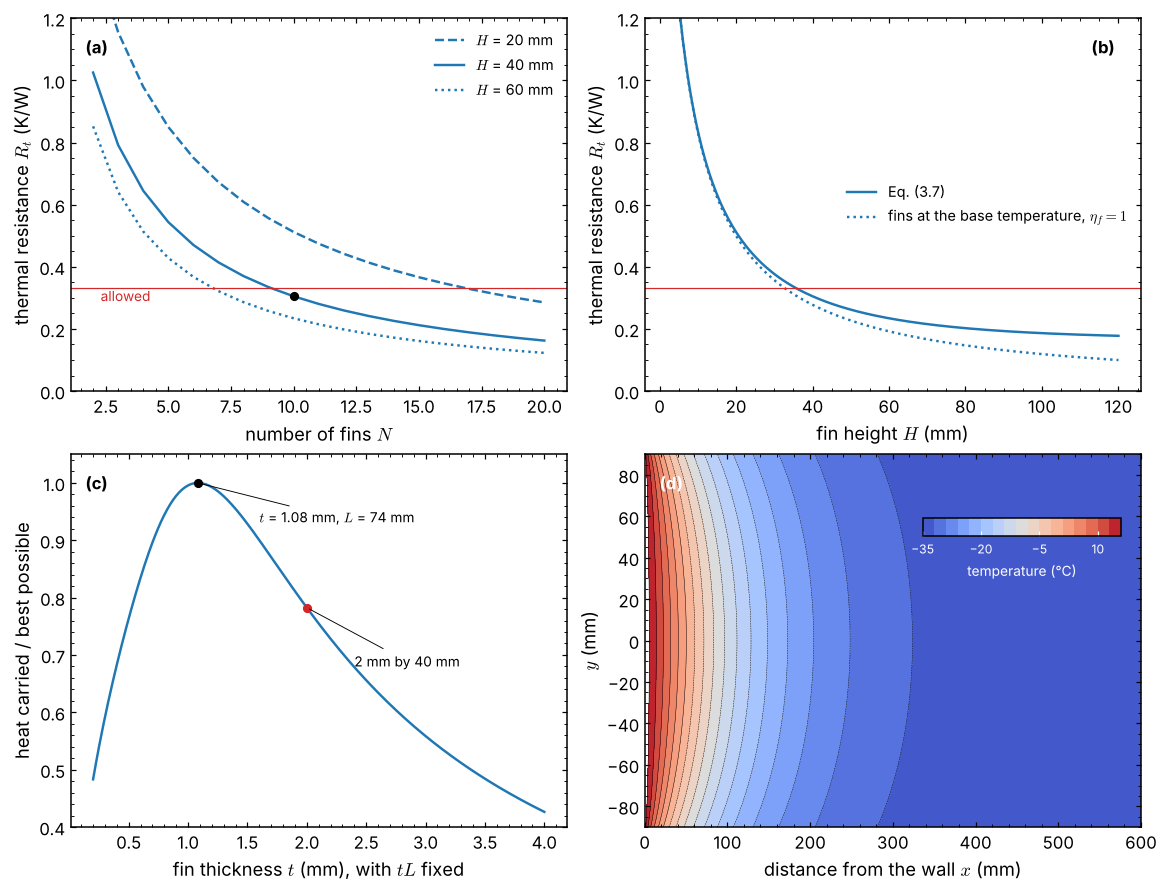

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
Ns = np.arange(2, 21)
for H, style in ((0.02, "--"), (0.04, "-"), (0.06, ":")):
    R_N = [fins.plate_fin_heat_sink(N, H, t_fin, length, width, k_al, h_air)["R"] for N in Ns]
    ax.plot(Ns, R_N, "C0" + style, label=f"$H$ = {1e3 * H:.0f} mm")
ax.axhline((T_max - T_air) / P_mod, color="C3", lw=0.8)
ax.text(2.3, 0.29, "allowed", color="C3", fontsize=9)
ax.plot([10], [sink["R"]], "ko", ms=5)
ax.set_xlabel("number of fins $N$")
ax.set_ylabel("thermal resistance $R_t$ (K/W)")
ax.set_ylim(0, 1.2)
ax.legend(loc="upper right")
panel_label(ax, "(a)")

ax = axes[0, 1]
Hs = np.linspace(0.002, 0.12, 200)
R_H = [fins.plate_fin_heat_sink(10, H, t_fin, length, width, k_al, h_air)["R"] for H in Hs]
R_ideal = [1 / (h_air * fins.plate_fin_heat_sink(10, H, t_fin, length, width, k_al, h_air)["A_t"]) for H in Hs]
ax.plot(Hs * 1e3, R_H, "C0", label=r"Eq. (3.7)")
ax.plot(Hs * 1e3, R_ideal, "C0:", label=r"fins at the base temperature, $\eta_f = 1$")
ax.axhline((T_max - T_air) / P_mod, color="C3", lw=0.8)
ax.set_xlabel("fin height $H$ (mm)")
ax.set_ylabel("thermal resistance $R_t$ (K/W)")
ax.set_ylim(0, 1.2)
ax.legend(loc="center right")
panel_label(ax, "(b)", x=0.9)

ax = axes[1, 0]
ts = np.linspace(0.2e-3, 4e-3, 300)
ax.plot(ts * 1e3, [q_plate(t) / q_plate(t_opt) for t in ts], "C0")
ax.plot([t_opt * 1e3], [1.0], "ko", ms=5)
ax.plot([t_fin * 1e3], [q_plate(t_fin) / q_plate(t_opt)], "o", color="C3", ms=5)
ax.annotate(f"$t$ = {1e3 * t_opt:.2f} mm, $L$ = {1e3 * A_p / t_opt:.0f} mm", (t_opt * 1e3, 1.0),
            (1.6, 0.93), fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.6))
ax.annotate("2 mm by 40 mm", (t_fin * 1e3, q_plate(t_fin) / q_plate(t_opt)), (2.4, 0.68), fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.6))
ax.set_xlabel("fin thickness $t$ (mm), with $tL$ fixed")
ax.set_ylabel("heat carried / best possible")
ax.set_ylim(0.4, 1.05)
panel_label(ax, "(c)")

ax = axes[1, 1]
xg = np.linspace(0, 0.6, 241)
yg = np.linspace(-b_slab, b_slab, 81)
X, Y = np.meshgrid(xg, yg)
T_field = T_out + theta_b * slab["theta"](X, np.abs(Y))
cs = ax.contourf(X * 1e3, Y * 1e3, T_field, levels=np.arange(-35, 19, 3), cmap="coolwarm")
ax.contour(X * 1e3, Y * 1e3, T_field, levels=np.arange(-35, 19, 3), colors="k", linewidths=0.3)
cax = ax.inset_axes([0.56, 0.78, 0.40, 0.05])
cbar = fig.colorbar(cs, cax=cax, orientation="horizontal", ticks=[-35, -20, -5, 10])
cbar.set_label("temperature (°C)", color="w", fontsize=9)
cbar.ax.tick_params(colors="w", labelsize=8)
ax.set_xlabel("distance from the wall $x$ (mm)")
ax.set_ylabel("$y$ (mm)")
panel_label(ax, "(d)", color="w")
plt.show()

**Figure 3.2.** (a) Thermal resistance of the heat sink against the number of 2 mm fins,
for three fin heights, Eq. (3.7); the horizontal line is the largest resistance that keeps
the base below 90 °C, and the point is the design chosen. (b) Resistance of the
ten-fin heat sink against fin height, compared with fins that are perfect conductors. (c)
Heat carried by a plate fin made from a fixed amount of metal, against its thickness; the
optimum (3.8) and the 2 mm by 40 mm fin are marked. (d) Temperature in the first 600 mm of
the concrete balcony slab, from the exact two-dimensional solution (3.9), with the root at
18 °C (left) and air at −35 °C on both faces.

## 3.6 Checks

`reference.plate_fin_2d_fv` solves the two-dimensional problem of Section 3.5 by finite
volumes on a uniform grid, with an adiabatic or a convective tip, and compares the heat
entering at the base with the heat leaving through the faces and the tip. Four checks
follow.

*The 2-D solutions.* The finite volumes converge to the series (3.9) for both fins
(Figure 3.3a). For the thin aluminium fin the error falls as the square of the cell size.
For the slab it falls a little more slowly, about as $\Delta^{1.7}$, because at the corner
where the root meets the face the fixed temperature and the convection disagree, and the
temperature gradient there is singular.

*The 1-D theory against 2-D.* For a long fin, the ratio of the 1-D heat to the exact heat
depends on Bi alone. Figure 3.3b shows that the 1-D theory overestimates the heat by about
Bi/6 when Bi is small.

*Temperatures in the slab.* Figure 3.3c,d compares the 2-D temperatures with the 1-D
profile along the slab and across its thickness.

In [8]:
def fv_error(L, b, k, h, ny_list, aspect):
    exact = reference.plate_fin_2d_series(L, b, k, h)["Q_per_K"]
    errors, balance = [], []
    for ny in ny_list:
        fv = reference.plate_fin_2d_fv(L, b, k, h, 1.0, 0.0, nx=int(round(aspect * ny)), ny=ny)
        errors.append(abs(fv["Q_base"] / exact - 1))
        balance.append(abs(fv["balance"]))
    return np.array(errors), max(balance)


ny_list = np.array([4, 8, 16, 32])
err_thin, bal_thin = fv_error(H_fin, t_fin / 2, k_al, h_air, ny_list, 12.5)
ny_slab = np.array([5, 10, 20, 40, 80])
err_slab, bal_slab = fv_error(L_slab, b_slab, k_c, h_out, ny_slab, 0.5 * L_slab / b_slab)
order = lambda e, n: np.polyfit(np.log(n), np.log(e), 1)[0]
print(f"thin aluminium fin: error {err_thin[-1]:.1e} with {ny_list[-1]} cells across, order {-order(err_thin, ny_list):.2f},"
      f" balance {bal_thin:.0e}")
print(f"balcony slab: error {err_slab[-1]:.1e} with {ny_slab[-1]} cells across, order {-order(err_slab[2:], ny_slab[2:]):.2f},"
      f" balance {bal_slab:.0e}")

Bis = np.logspace(-3, 1, 25)
excess_long, excess_short = [], []
for B in Bis:                      # b = k = 1, so h = Bi and m = sqrt(Bi)
    for mL_val, out in ((40.0, excess_long), (1.0, excess_short)):
        L_val = mL_val / math.sqrt(B)
        exact = reference.plate_fin_2d_series(L_val, 1.0, 1.0, B)["Q_per_K"]
        out.append(math.sqrt(B) * math.tanh(mL_val) / exact - 1)
excess_long, excess_short = np.array(excess_long), np.array(excess_short)
for B in (0.01, 0.1, 1.0):
    print(f"Bi = {B:5.2f}: 1-D too high by {np.interp(math.log(B), np.log(Bis), excess_long):.2%} (long fin)")
print(f"1-D within 1 % of the exact heat for Bi < {np.interp(0.01, excess_long, Bis):.3f}")
fin_2d = reference.plate_fin_2d_series(Hc, t_fin / 2, k_al, h_air)["Q_per_K"]
print(f"heat-sink fin: 1-D / 2-D - 1 = {math.sqrt(h_air * k_al * t_fin / 2) * math.tanh(m * Hc) / fin_2d - 1:.1e}")
core_face = theta_b * (slab["theta"](0.05, 0.0) - slab["theta"](0.05, b_slab))
x_cross = brentq(lambda x: slab["theta"](x, b_slab) - math.exp(-m_slab * x), 0.01, 0.5)
print(f"slab, 50 mm from the wall: core {core_face:.1f} K warmer than the faces;"
      f" the face is colder than the 1-D fin up to x = {1e3 * x_cross:.0f} mm, warmer beyond")

thin aluminium fin: error 3.6e-07 with 32 cells across, order 1.99, balance 9e-11
balcony slab: error 2.7e-04 with 80 cells across, order 1.75, balance 6e-13
Bi =  0.01: 1-D too high by 0.16% (long fin)
Bi =  0.10: 1-D too high by 1.44% (long fin)
Bi =  1.00: 1-D too high by 10.76% (long fin)
1-D within 1 % of the exact heat for Bi < 0.068
heat-sink fin: 1-D / 2-D - 1 = 6.0e-05
slab, 50 mm from the wall: core 9.8 K warmer than the faces; the face is colder than the 1-D fin up to x = 211 mm, warmer beyond


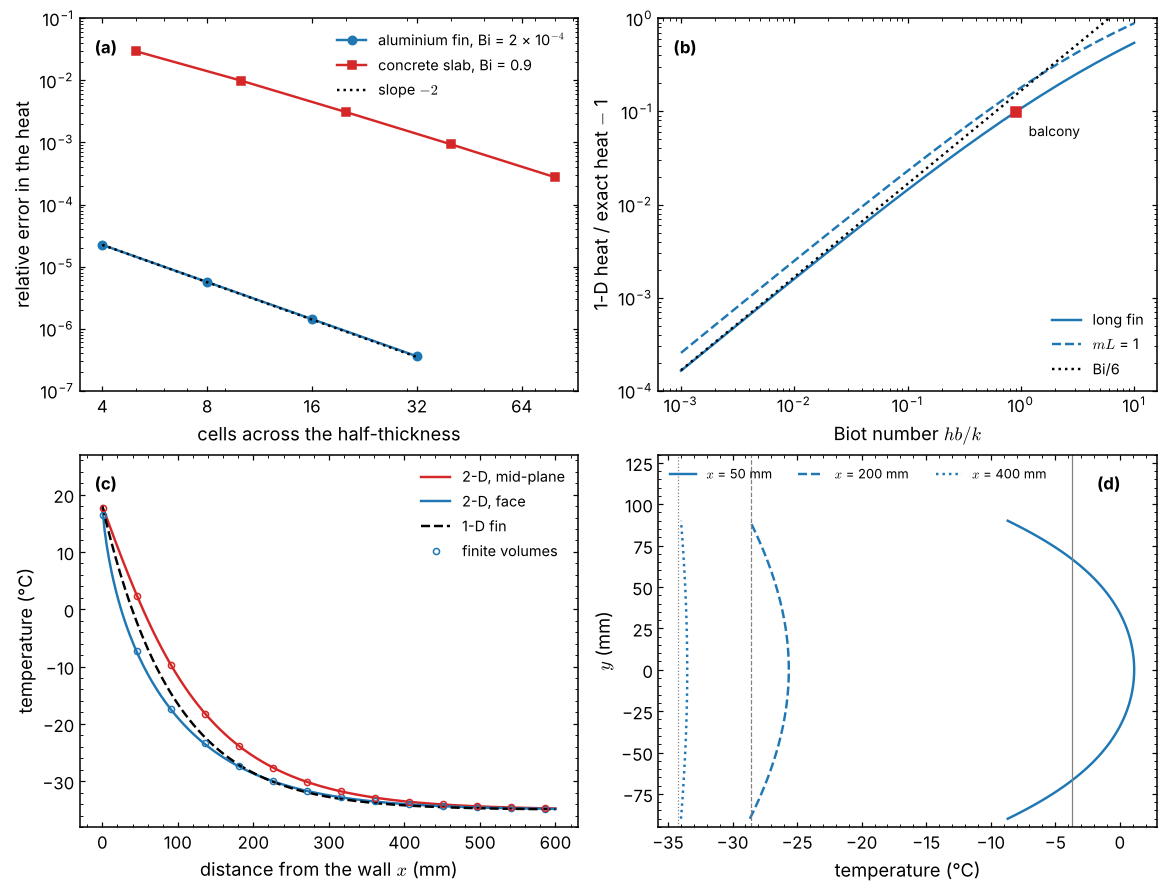

In [9]:
fv_slab = reference.plate_fin_2d_fv(L_slab, b_slab, k_c, h_out, T_root, T_out, nx=667, ny=40)
x_line = np.linspace(0, 0.6, 200)
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
ax.loglog(ny_list, err_thin, "o-", label="aluminium fin, Bi = 2 × 10$^{-4}$")
ax.loglog(ny_slab, err_slab, "s-", color="C3", label="concrete slab, Bi = 0.9")
ax.loglog(ny_list, err_thin[0] * (ny_list[0] / ny_list) ** 2, "k:", label=r"slope $-2$")
ax.set_xlabel("cells across the half-thickness")
ax.set_ylabel("relative error in the heat")
ax.set_xticks([4, 8, 16, 32, 64])
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylim(1e-7, 1e-1)
ax.legend(loc="upper right")
panel_label(ax, "(a)")

ax = axes[0, 1]
ax.loglog(Bis, excess_long, "C0", label="long fin")
ax.loglog(Bis, excess_short, "C0--", label="$mL$ = 1")
ax.loglog(Bis, Bis / 6, "k:", label="Bi/6")
ax.plot([Bi], [q_1d / q_2d - 1], "s", color="C3", ms=6)
ax.text(Bi * 1.3, (q_1d / q_2d - 1) * 0.55, "balcony", ha="left", fontsize=9)
ax.set_xlabel("Biot number $hb/k$")
ax.set_ylabel("1-D heat / exact heat $-$ 1")
ax.set_ylim(1e-4, 1)
ax.legend(loc="lower right")
panel_label(ax, "(b)")

ax = axes[1, 0]
ax.plot(x_line * 1e3, T_out + theta_b * slab["theta"](x_line, 0.0), "C3", label="2-D, mid-plane")
ax.plot(x_line * 1e3, T_out + theta_b * slab["theta"](x_line, b_slab), "C0", label="2-D, face")
ax.plot(x_line * 1e3, T_out + theta_b * np.exp(-m_slab * x_line), "k--", label="1-D fin")
sel = fv_slab["x"] < 0.6
ax.plot(fv_slab["x"][sel][::20] * 1e3, fv_slab["T"][-1, sel][::20], "o", color="C0", ms=4, mfc="none",
        label="finite volumes")
ax.plot(fv_slab["x"][sel][::20] * 1e3, fv_slab["T"][0, sel][::20], "o", color="C3", ms=4, mfc="none")
ax.set_xlabel("distance from the wall $x$ (mm)")
ax.set_ylabel("temperature (°C)")
ax.set_ylim(-38, 27)
ax.legend(loc="upper right")
panel_label(ax, "(c)")

ax = axes[1, 1]
yy = np.linspace(-b_slab, b_slab, 101)
for x0, style in ((0.05, "-"), (0.2, "--"), (0.4, ":")):
    ax.plot(T_out + theta_b * slab["theta"](x0, np.abs(yy)), yy * 1e3, "C0" + style, label=f"$x$ = {1e3 * x0:.0f} mm")
    ax.axvline(T_out + theta_b * math.exp(-m_slab * x0), color="0.5", lw=0.8, ls=style)
ax.set_xlabel("temperature (°C)")
ax.set_ylabel("$y$ (mm)")
ax.set_ylim(-95, 130)
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
panel_label(ax, "(d)", x=0.88)
plt.show()

**Figure 3.3.** Checks. (a) Relative error of the heat entering the fin from 2-D finite
volumes, against the exact series (3.9), as the grid is refined; the dotted line has slope
−2. (b) How much the 1-D theory overestimates the heat, against the Biot number, for a
long fin and for $mL = 1$; the square is the balcony slab. (c) Temperature along the slab
at its mid-plane and at its faces, from the series and from finite volumes, and the 1-D
profile. (d) Temperature across the slab at three distances from the wall (curves), and
the uniform temperature of the 1-D theory at the same places (vertical lines).

The finite volumes and the series agree to $4 \times 10^{-7}$ for the aluminium fin and
to $3 \times 10^{-4}$ for the slab, and the energy balances close to $10^{-10}$ or better.
For the aluminium fin of the heat sink the exact 2-D heat is within $6 \times 10^{-5}$ of
the 1-D theory, so Eqs. (3.3)–(3.7) are exact for practical purposes. The 1-D theory stays
within 1 % up to $\mathrm{Bi} = 0.07$ and is 10 % too high at the slab's
$\mathrm{Bi} = 0.9$. Figure 3.3d shows why: 50 mm from the wall the core of the slab is
10 K warmer than its faces. Up to about 210 mm from the wall the faces are colder than the
1-D fin, and beyond it warmer (Figure 3.3c), because the slab carries its heat further
before it reaches the faces.

## 3.7 What to trust

* *The heat transfer coefficient.* Equation (3.7) takes one $h$ for every surface. Real
  heat sinks have a higher $h$ near the leading edge and at the fin tips, and a lower one
  deep in narrow gaps, and the air warms as it flows along the fins. Measured fin
  efficiencies are usually a few per cent below the uniform-$h$ value. Getting $h$ is the
  job of Part II.
* *What the heat sink leaves out.* The resistance of the thermal paste between module and
  base (often 0.05–0.1 K/W), spreading in the base when the module is smaller than it, and
  radiation, which helps a black anodised heat sink by 5–10 % in still air but little with
  a fan.
* *The balcony.* The root temperature of 18 °C is an assumption, and real slabs are 3-D,
  with steel bars that conduct far better than concrete. Building codes assess such
  *thermal bridges* with 2-D or 3-D models of the whole junction (ISO 10211). The point of
  the section is the size of the leak, a few hundred watts per metre, and the test of the
  1-D theory.
* *The 1-D fin.* It is within 1 % when $\mathrm{Bi} = hb/k < 0.07$,
  which holds for metal fins in gases. For thick fins of poor conductors, or for metal fins
  in boiling liquids, check it against the 2-D solution.

## Summary

* With the temperature uniform across its section, a fin obeys $\theta'' = m^2\theta$ with
  $m = \sqrt{hP/kA_c}$, Eq. (3.2); $1/m$ is the length over which it works.
* With an adiabatic tip, $q_f = \sqrt{hPkA_c}\,\theta_b \tanh mL$, Eq. (3.3); a convective
  tip is handled by the corrected length $L + A_c/P$, Eq. (3.4).
* The efficiency $\tanh mL_c/mL_c$ and the effectiveness $\sqrt{kP/hA_c}\tanh mL_c$,
  Eqs. (3.5)–(3.6), say how well a fin uses its area and whether it is worth adding.
* An array of fins has the resistance $1/\eta_o hA_t$, Eq. (3.7).
* For a fixed amount of metal, a plate fin carries the most heat at $mL = 1.4192$,
  Eq. (3.8), where it is only 63 % efficient.
* The 1-D theory overestimates the heat by about Bi/6, Bi $= hb/k$; the exact 2-D solution
  is Eqs. (3.9)–(3.10).

## Exercises

Sample solutions are in [`solutions/part1_conduction/03_solutions.ipynb`](../../solutions/part1_conduction/03_solutions.ipynb).

1. **A thermometer well.** A thermocouple measures the temperature of hot gas in a duct.
   It sits at the closed end of a stainless steel tube ($k = 16$ W/(m K), outer diameter
   10 mm, inner diameter 7 mm) that reaches 100 mm into the gas from the duct wall. The gas
   is at 300 °C, the wall at 200 °C, and $h = 30$ W/(m² K) on the outside of the tube.
   Treating the tube as a fin with an adiabatic tip, how much too low does the thermocouple
   read? How long must the tube be for an error below 0.5 K? Would carbon steel
   ($k = 50$ W/(m K)) be better?
2. **A thermal break.** The balcony slab of Section 3.5 is cut at the wall, and the
   80 mm gap filled with a block of insulation crossed by steel bars, with an effective
   conductivity of 0.20 W/(m K) over the full 180 mm thickness. Treat the block as a
   resistance in series with the slab outside it (a long fin with the 2-D heat of
   Section 3.5), and find the new heat loss per metre. Is the 2-D correction to the fin
   still worth making?
3. **Which side to fin?** Find the effectiveness (3.6) of long plate fins 1 mm thick in
   three cases: aluminium in air ($h = 40$ W/(m² K)); aluminium in water
   ($h = 5000$ W/(m² K)); stainless steel ($k = 16$ W/(m K)) in boiling water
   ($h = 20\,000$ W/(m² K)). A fin with $\varepsilon_f < 1$ would insulate the surface.
   Check the last case with the 2-D series: is the 1-D answer right?
4. **Annular fins.** The tubes of an air heater carry circular fins: aluminium, 0.4 mm
   thick, from the tube radius $r_1 = 12.5$ mm to $r_2 = 27.5$ mm, with
   $h = 50$ W/(m² K). The fin equation becomes
   $\frac{1}{r}\frac{d}{dr}\left(r\frac{d\theta}{dr}\right) = m^2\theta$. Solve it with
   modified Bessel functions (adiabatic tip at the corrected radius $r_2 + t/2$) to find
   the efficiency, check the result with `scipy.integrate.solve_bvp`, and compare it with
   a straight fin of the same height. Why is the straight fin optimistic?

## Suggested references

* D. R. Harper and W. B. Brown, *Mathematical Equations for Heat Conduction in the Fins
  of Air-Cooled Engines*, NACA Report No. 158 (1923).
* E. Schmidt, "Die Wärmeübertragung durch Rippen", *Z. VDI* **70**, 885 and 947 (1926).
* K. A. Gardner, "Efficiency of extended surface", *Trans. ASME* **67**, 621 (1945).
* A. D. Kraus, "Sixty-five years of extended surface technology (1922–1987)", *Appl.
  Mech. Rev.* **41**, 321 (1988).
* A. D. Kraus, A. Aziz and J. Welty, *Extended Surface Heat Transfer* (Wiley, 2001).
* ISO 10211:2017, *Thermal bridges in building construction — Heat flows and surface
  temperatures — Detailed calculations* (International Organization for Standardization,
  2017).

---

**Previous:** [2. Steady conduction and thermal resistance](02_steady_conduction.ipynb) &nbsp;·&nbsp; **Next:** [4. Two-dimensional steady conduction](04_two_dimensional.ipynb)